# 01 — Preprocessing · Yost et al. 2019 (Cutaneous Basal Cell Carcinoma, 10x)

Load malignant cells -> per-sample cell-count threshold (gap-finding) -> overdispersed genes -> PCA -> Harmony integration on `sample` (theta swept) -> neighbours -> UMAP -> island removal -> lobe/cell-cycle biology -> **Gate 1** (sample-mixed AND continuous, judged on the regenerated embedding + iLISI).

*Leaf resolution:* `Data_Yost2019_Skin/` nests two technology leaves — **BCC** (all 3,551 malignant cells) and **SCC** (T-cells only, 0 malignant). The malignant compartment is the BCC leaf.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'   # scFates PPT -> rpy2 -> r-mgcv
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

### Paths (notebooks run in place, two levels below Puram under the `<Category>/` partition)

In [2]:
name = os.path.basename(os.getcwd())                    # Yost2019_Skin
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Skin
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name, 'BCC')   # BCC leaf = malignant compartment
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Yost2019_Skin | category: Skin


### Load malignant cells

In [3]:
adata = load_CCCA_adata(pth_in)
print('full BCC atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Yost2019_Skin/BCC
Done.
full BCC atlas: (53030, 23309)
malignant: (3551, 23309) | samples: 16
expression: X max 6.96 (log1p of normalize_total UMI counts)


### Per-sample threshold by gap-finding
Sort per-sample malignant counts; find the largest count ratio (cliff). A *dominant* cliff (top ratio >=1.5x the runner-up and the sample below it under 2x the floor) marks batch spillover -> cut at the geometric mean of the cliff; otherwise fall back to the >=100 floor. Derived from this dataset, shown not asserted.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1]/vals[1:]; gap = int(np.argmax(ratios))
srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]; FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
thresh = int(np.sqrt(vals[gap]*vals[gap+1])) if dominant else FLOOR
print(f'threshold = {thresh}' + (' (geometric-mean of dominant cliff)' if dominant else ' (>= floor)'))
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: {'su006_pre': np.int64(1403), 'su008_pre': np.int64(816), 'su003_post': np.int64(598), 'su006_post': np.int64(320), 'su005_pre': np.int64(254), 'su007_pre': np.int64(48), 'su004_post': np.int64(37), 'su008_post': np.int64(24), 'su001_pre': np.int64(18), 'su003_pre': np.int64(13), 'su002_pre': np.int64(8), 'su007_post': np.int64(6), 'su010_post': np.int64(2), 'su005_post': np.int64(2), 'su004_pre': np.int64(1), 'su010_pre': np.int64(1)}
gap ratios: ['1403->816:1.72', '816->598:1.36', '598->320:1.87', '320->254:1.26', '254->48:5.29', '48->37:1.30', '37->24:1.54', '24->18:1.33', '18->13:1.38', '13->8:1.62', '8->6:1.33', '6->2:3.00', '2->2:1.00', '2->1:2.00', '1->1:1.00']
argmax gap 254->48 (ratio 5.29); top/second = 1.76; dominant cliff = True
threshold = 110 (geometric-mean of dominant cliff)
kept 5/16 samples (min per-sample = 254) -> 3391 cells


### Overdispersed genes -> PCA -> Harmony theta-sweep
Integration strength swept on the same-sample nearest-neighbour fraction (lower = better mixed). BCC is strongly patient-segregated pre-Harmony; mixing improves sharply to theta=5 then flattens — theta=5 chosen (strongest integration before the plateau, without over-smoothing structure).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
def _same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20]); sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base, '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 5
print('selected theta =', theta, '(mixing improves sharply to theta=5 then flattens; theta=10 within noise)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1007 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1007
same-sample neighbour fraction | pre-Harmony 0.942 | sweep {2: 0.529, 5: 0.406, 10: 0.41}
selected theta = 5 (mixing improves sharply to theta=5 then flattens; theta=10 within noise)


### Island removal (radius-graph connected components; keep the largest)

In [6]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('after island removal:', adata.shape[0], 'cells')

removed 0 cells in 0 detached islands
after island removal: 3391 cells


### Sub-region biology BEFORE Gate 1 — lobes, cell cycle, proliferation
Settle each manifold sub-region identity before certifying continuity. Leiden lobes checked for a cycling / proliferation compartment that would need scoping out (the Kürten lobe-identity fork).

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('cycling fraction per lobe:', adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('proliferation score per lobe:', adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict())
# no proliferation-dominated lobe (all prolif scores negative, cycling ~10%): single low-cycling body
adata.obs['compartment'] = pd.Categorical(['Body']*adata.shape[0])
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'0': 1547, '1': 1255, '2': 589}
overall cycling fraction: 0.106
cycling fraction per lobe: {'0': 0.121, '1': 0.124, '2': 0.025}
proliferation score per lobe: {'0': -0.108, '1': -0.061, '2': -0.164}
compartments: {'Body': 3391}


### Module signatures + graph-smoothed geography (analysis aid; deliverable panels show raw)

In [8]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
print('raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('lobe smoothed means:'); print(adata.obs.groupby('lobe', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(3))
print('smoothed spatial correlations:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.3f}')

Gast: 75/81 genes present
pSom: 89/98 genes present
Crest: 98/104 genes present
raw module means: {'Gast': -0.0147, 'pSom': 0.0457, 'Crest': -0.0109}
lobe smoothed means:
      Gast_sm  pSom_sm  Crest_sm
lobe                            
0      -0.022    0.037     0.002
1      -0.006    0.056    -0.023
2      -0.020    0.044    -0.015
smoothed spatial correlations:
  Gast_sm vs pSom_sm: r = +0.607
  Crest_sm vs Gast_sm: r = -0.821
  Crest_sm vs pSom_sm: r = -0.842


### House linear orientation (rigid rotation; Gast/pSom origin pole -> left)

In [9]:
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max()/c.std(0).min()
_,_,vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot),-np.sin(-theta_rot)],[np.sin(-theta_rot),np.cos(-theta_rot)]])
xyr = c @ Rm.T
origin_score = (adata.obs['Gast_sm'].values + adata.obs['pSom_sm'].values) - adata.obs['Crest_sm'].values
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}; rigid rotation {np.degrees(theta_rot):+.1f}deg; origin pole on left -> X_umap_lin')

manifold aspect (max/min std): 1.53; rigid rotation -1.9deg; origin pole on left -> X_umap_lin


### Gate 1 — mixing (iLISI) on one continuous manifold

In [10]:
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one continuous manifold (one connected component, no islands removed).')
print('GATE 1: samples intermix per-neighbourhood on one continuous manifold -> GO')

iLISI median: pre-Harmony 1.02 -> post-Harmony(theta=5) 3.21 of 5 samples
5 samples share one continuous manifold (one connected component, no islands removed).
GATE 1: samples intermix per-neighbourhood on one continuous manifold -> GO


### Save processed.h5ad

In [11]:
protect = {'sample','compartment','lobe','celltype','cell_type','cell_cycle_phase','source','disease','patient'}
for col in list(adata.obs.columns):
    if col in protect:
        adata.obs[col] = adata.obs[col].astype(str).astype('category'); continue
    s = adata.obs[col]
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        adata.obs[col] = conv if (s.notna().sum()>0 and conv.notna().sum() >= 0.9*s.notna().sum()) else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (3391, 19267)


### `samples.pdf` — single sample-coloured manifold UMAP (house `(3.5,1.5)` strip, house orientation)

saved samples.pdf | cells: 3391


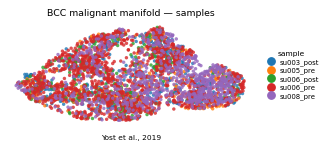

In [12]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('BCC malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Yost et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])